# Peaks, indexing and a Le Bail check

When the phase is unknown there is no CIF to start from, and the cell has to come from the peak positions alone.
We pick the peaks of a synthetic pattern whose answer we know, index them, and read how rietx decides whether to name a single cell.
Then we check the best candidate with a Le Bail fit.
By the end you can pick and fit peaks, run an indexing search, and test a candidate cell against the whole pattern.

*Written by Claude Code, Anthropic's coding agent, for the rietx project.*

**You need** rietx 1.10 or later, which the next cell installs.
Notebook 01 introduces Le Bail fitting.

**The data** is synthetic aragonite, CaCO₃, made from its published structure: Dal Negro and Ungaretti (1971), *American Mineralogist* 56, 768, as entry 9000229 of the Crystallography Open Database (public domain).
The displacement parameters are the isotropic equivalents of that entry's anisotropic ones.

**Runtime** is under a minute on a laptop, most of it the indexing search.

In [ ]:
%pip install rietx

## A synthetic pattern

Write aragonite's structure to a CIF and read it back.

In [1]:
import tempfile
from pathlib import Path

import numpy as np

import rietx as rx
from rietx.indexing import SearchSpec, structure_from_candidate

work = Path(tempfile.mkdtemp())
cif = work / "aragonite.cif"
cif.write_text(
    "data_aragonite\n_space_group_name_H-M_alt 'P m c n'\n"
    "_cell_length_a 4.9616\n_cell_length_b 7.9705\n_cell_length_c 5.7394\n"
    "_cell_angle_alpha 90\n_cell_angle_beta 90\n_cell_angle_gamma 90\n"
    "loop_\n_atom_site_label\n_atom_site_type_symbol\n_atom_site_fract_x\n"
    "_atom_site_fract_y\n_atom_site_fract_z\n_atom_site_B_iso_or_equiv\n"
    "Ca1 Ca 0.25 0.4151 0.2403 0.67\n"
    "C1  C  0.25 0.7627 0.0850 0.80\n"
    "O1  O  0.25 0.9231 0.0952 1.25\n"
    "O2  O  0.4729 0.6801 0.0870 1.19\n",
    encoding="utf-8",
)
truth = rx.Structure.from_cif(cif)

[`predict`](https://rietx.org/docs/stable/reference/refinement.html#entry-points) computes a pattern from a structure and an instrument without fitting anything.
This instrument sets its own peak widths and a flat background of 200 counts.
We scale the phase so the strongest peak reaches about 20 000 counts above the background, then draw Poisson counts.

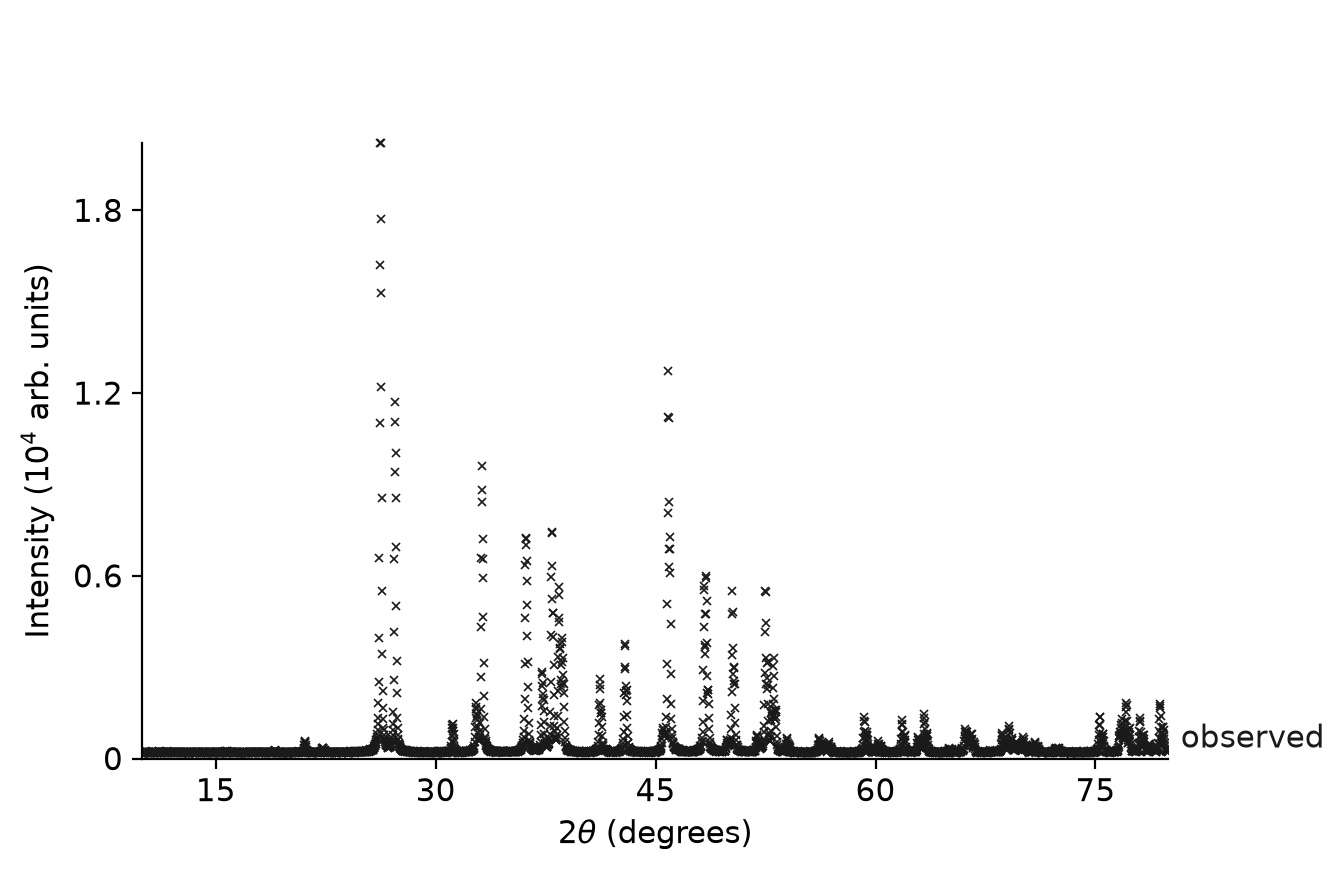

In [2]:
true_instrument = rx.Instrument.bragg_brentano(radiation="CuKa")
true_instrument.profile.w.value = 0.004
true_instrument.profile.x.value = 0.05
true_instrument.background = rx.BackgroundChebyshev.with_terms(1)
true_instrument.background.coefficients[0].value = 200.0

two_theta = np.arange(10, 80, 0.02)
y = rx.Refinement(truth, true_instrument).predict(two_theta) - 200.0
truth.phases[0].scale.value *= 20000 / y.max()
y = rx.Refinement(truth, true_instrument).predict(two_theta)
data = rx.PatternData(
    two_theta=two_theta,
    intensity=np.random.default_rng(0).poisson(y).astype(float),
)
data.plot()

From here on we pretend not to know the structure.
The indexer should find the CIF's cell, perhaps with its axes in another order.

## Find the peaks

[`pick_peaks`](https://rietx.org/docs/stable/reference/peaks.html#picking-the-peaks) finds every resolvable peak and fits each one for its position, with an esd.
It needs an instrument for the wavelength and a first guess at the peak width.
Give it a default copper instrument, as you would for an unknown sample.
Its widths do not match these peaks, so expect the picker to say so.

In [3]:
lab = rx.Instrument.bragg_brentano(radiation="CuKa")
peaks = rx.pick_peaks(data, lab)
peaks

PeakList: 100 peaks, 54 usable, 10–79.98° 2θ, λ = 1.54059 Å, source fitted
    #   two_theta  two_theta_esd   intensity    fwhm  origin   flags
    0     21.0733         0.0025        31.5   0.106  fitted
    1     22.2914         0.0056         9.7   0.078  fitted
    2     26.2221         0.0003      2174.3   0.095  fitted   asymmetry_unmodelled
    3     26.6070         0.0104        19.6   0.097  fitted   asymmetry_unmodelled
    4     27.2200         0.0003      1236.9   0.097  fitted   asymmetry_unmodelled
    5     31.1394         0.0015        95.0   0.108  fitted
    6     32.7500         0.0012       169.8   0.097  fitted   asymmetry_unmodelled
    7     32.7501      1962.1099        32.3   0.097  fitted   unresolved_shoulder, not_separable, no_intensity, position_unmeasured, asymmetry_unmodelled
    8     32.7501       462.5768       136.9   0.097  fitted   unresolved_shoulder, no_intensity, position_unmeasured, asymmetry_unmodelled
    9     33.1521         0.0004      1063.5   0.097  fitted   asymmetry_unmodelled
   10     33.1522         0.0004      1065.8   0.097  fitted   asymmetry_unmodelled, duplicate_line
   11     36.1488         0.0006       946.7   0.125  fitted
   12     37.2579         0.0024       323.6   0.098  fitted   duplicate_line
   13     37.2650         0.0011       298.2   0.100  fitted   asymmetry_unmodelled
   14     37.8984         0.0334       958.3   0.117  fitted   duplicate_line
   15     37.9064         0.0041       848.5   0.100  fitted   asymmetry_unmodelled, duplicate_line
   16     37.9071         0.0004       869.0   0.097  fitted   asymmetry_unmodelled
   17     37.9074         0.0005       866.2   0.098  fitted   asymmetry_unmodelled, duplicate_line
   18     38.3949         0.0069       551.9   0.117  fitted   duplicate_line
   19     38.4023         0.0005       618.3   0.097  fitted   asymmetry_unmodelled
   20     38.4033         0.0006       642.5   0.098  fitted   asymmetry_unmodelled, duplicate_line
   21     38.5784         0.0099       377.6   0.117  fitted   position_at_bound, duplicate_line
   22     38.6307         0.0007       402.6   0.097  fitted
   23     41.1956         0.0008       271.1   0.093  fitted   asymmetry_unmodelled
   24     42.9067         0.0008       426.2   0.099  fitted
   25     45.4857         0.0022        71.0   0.097  fitted
   26     45.4858         0.0031        70.5   0.097  fitted   asymmetry_unmodelled, duplicate_line
   27     45.8585         0.0003      1528.8   0.097  fitted
   28     45.8585         0.0004      1529.6   0.097  fitted   asymmetry_unmodelled, duplicate_line
   29     48.3096         0.0007       643.1   0.099  fitted   fit_failed, asymmetry_unmodelled
   30     48.3098         0.0008       633.4   0.099  fitted
   31     48.4600         0.0011       420.1   0.099  fitted   position_at_bound
   32     48.4659         9.7793       264.3   0.099  fitted   fit_failed, no_intensity, asymmetry_unmodelled
   33     48.4659        17.6743       145.6   0.099  fitted   fit_failed, unresolved_split, no_intensity, asymmetry_unmodelled, kalpha2_residual
   34     49.8874         0.0051        33.4   0.099  fitted   asymmetry_unmodelled
   35     49.9000         0.0061        32.3   0.099  fitted   position_at_bound, axial_tail, asymmetry_unmodelled, duplicate_line
   36     50.2395         0.0006       624.5   0.099  fitted
   37     50.2396         0.0007       626.3   0.099  fitted   asymmetry_unmodelled, duplicate_line
   38     51.9124         0.0035        56.9   0.097  fitted   asymmetry_unmodelled
   39     52.4903         0.0012       656.6   0.097  fitted   asymmetry_unmodelled, duplicate_line
   40     52.4910         0.0019       675.9   0.095  fitted   asymmetry_unmodelled, duplicate_line
   41     52.4911         0.0004       665.8   0.097  fitted
   42     52.9157         0.0013       146.2   0.097  fitted
   43     52.9163         0.0062       143.9   0.095  fitted   asymmetry_unmodelled, duplicate_line
   44     

Each row is one peak: its position, the esd of that position, its area and its width.
[`flags`](https://rietx.org/docs/stable/reference/peaks.html#the-flags) records anything the fit noticed.
Some flags, such as `duplicate_line` and `fit_failed`, take a row out of indexing.
The header line counts the rows left usable.

The diagnostics under the table explain the list.
[`PEAK_WIDTH_LAW_MISMATCH`](https://rietx.org/docs/stable/reference/diagnostics-indexing.html#peak-width-law-mismatch) says the default instrument predicts narrower peaks than these, so the picker scaled its windows to the data.
[`PEAK_KALPHA2_ALIAS`](https://rietx.org/docs/stable/reference/diagnostics-indexing.html#peak-kalpha2-alias) lists candidates dropped as the Kα2 partner of a stronger line, so each reported position is a Kα1 position.
Open a diagnostic to read what its code means.
[Diagnostics: peaks and indexing](https://rietx.org/docs/stable/reference/diagnostics-indexing.html) lists every code.

## Measure lines you name

[`fit_peaks`](https://rietx.org/docs/stable/reference/peaks.html#fitting-peaks-you-name) fits exactly the positions you give it, and nothing else.
Use it to measure lines you have chosen: a few reflections for a size analysis, or one line as a quick check.

In [4]:
chosen = rx.fit_peaks(data, lab, [26.22, 27.22, 33.13])
chosen

PeakList: 3 peaks, 3 usable, 10–79.98° 2θ, λ = 1.54059 Å, source fitted
    #   two_theta  two_theta_esd   intensity    fwhm  origin   flags
    0     26.2221         0.0003      2174.3   0.095  manual   asymmetry_unmodelled
    1     27.2200         0.0006      1241.3   0.096  manual   asymmetry_unmodelled, unnamed_neighbour
    2     33.1512         0.0031      1110.2   0.092  manual   asymmetry_unmodelled, unnamed_neighbour
  warning[PEAK_ASYMMETRY_UNMODELLED]: 3 line(s) leave a significant odd residual after fitting.
    at: 26.2221°, 27.2200°, 33.1512°
    help: Set instrument.geometry.axial_sl and axial_hl to the real aperture ratios, then re-pick.
  warning[PEAK_WIDTH_LAW_MISMATCH]: The measured FWHM of 0.1566° differs by a factor of 4.9 from the 0.0322° that the instrument's U, V, W, X and Y predict. Seeds and windows were scaled by 4.87 to match the data.
    at: median of the 12 most prominent lines
    help: Run lab_calibrate on a standard, or set U, V, W, X and Y from one. A factor near 13 means the ProfileTCHZ default (W = 1e-3 deg²), a synchrotron line, is still in place.
  info[PEAK_KALPHA2_ALIAS]: 30 candidate(s) were dropped as the Kα2 maximum of a stronger line, so each reported position is a Kα1 position.
    at: 33.2400°, 38.0200°, 38.5000°, 38.7400°, 41.3000°, 43.0200°, 45.9800°, 48.6000°, 50.3800°, 52.0600°, 52.6400°, 53.2000°, 54.1200°, 56.3000°, 56.9600°, 59.4000°, 60.3400°, 61.9800°, 63.0800°, 63.5200°, 66.7200°, 68.8200°, 69.3000°, 69.7800°, 70.2800°, 71.0800°, 75.5000°, 77.3400°, 78.2600°, 79.6400°
    help: Confirm with an incident-side monochromator (Instrument.bragg_brentano with Kα1-only radiation) if one of these lines matters.

Each line is marked `manual`, because its position came from you.
A line flagged [`unnamed_neighbour`](https://rietx.org/docs/stable/reference/peaks.html#the-neighbour-you-did-not-name) shares its fitting window with a line you did not name, and that line's intensity had nowhere to go but into it.
A whole peak list rebuilt from edited positions in code meets this at every line it leaves out.

## The same work in the GUI

Editing a peak list is easier by hand, and rietx has a graphical mode for it.
Run [`rietx gui`](https://rietx.org/docs/stable/reference/cli.html#rietx-gui) in a terminal, open or create a project with your pattern, and choose the Peaks tab.
The plot then becomes an editing surface:

| Gesture | Does |
|---|---|
| click empty space | add a line, measured by `fit_peaks` |
| drag a marker | move it |
| shift-click | exclude a line from indexing |
| right-click | remove it |

The same tab runs the indexing search, draws a candidate's predicted lines over the pattern, and adopts a candidate as the starting point of a Le Bail fit.
Every gesture also has a typed equivalent in the panel.
[The GUI panel by panel](https://rietx.org/docs/stable/reference/gui-guide.html#peaks) covers the tab in full.

## Index

[`index_pattern`](https://rietx.org/docs/stable/reference/indexing.html#running-the-search) searches for cells that index the usable peaks.
A search over every crystal system can take minutes, so we narrow it.
[`SearchSpec`](https://rietx.org/docs/stable/reference/indexing.html#the-search-specification) limits it to orthorhombic cells, with a volume between 200 and 250 Å³ and no axis longer than 8.5 Å.
Those limits come from knowing the answer.
With a real unknown, start from the formula and a wide window, and let the search run longer.

[`budget_seconds`](https://rietx.org/docs/stable/reference/indexing.html#presets-budgets-and-the-three-states-of-a-system) caps each engine's search of each crystal system, and its default is 30 s.
This search finishes inside that on a quiet laptop.
On a laptop running other work, one engine ran past 30 s and the whole call took 58 s.
A search stopped by its cap cannot rule anything out, so we allow 120 s.

In [5]:
spec = SearchSpec(
    systems=("orthorhombic",),
    min_volume=200,
    max_volume=250,
    max_d_axis=8.5,
    budget_seconds=120,
)
indexing = rx.index_pattern(peaks, data=data, instrument=lab, spec=spec)
indexing

engines: dichotomy, svd, trial_error   systems: orthorhombic   lines: 54   validated: yes

 1. [ high ] orthorhombic P   4.96157 5.73930 7.97039 Å  90.000 90.000 90.000°   V = 226.96 Å³
      found by dichotomy, svd, trial_error;  indexed 51/54 lines;  chi2_red 0.46;  Pawley Rwp 0.0444, 24 of 87 lines absent

CELL: orthorhombic P 4.96157 5.73930 7.97039 Å 90.000 90.000 90.000°
  info[PEAK_POSITION_PRECISION]: The median σ(2θ) is 0.0015° and the worst is 0.0169°. The median σ(Q)/Q is 5.31e-05 and σ(Q) is 0.002 of the mean line spacing.
    at: 2θ 10.00-79.98°
  info[INDEX_SHIFT_FROM_PAIRS]: A systematic shift of 0.0043° 2θ was measured from 8 harmonic reflection pairs agreeing to 0.0030° (of 14 admitted, z = 8.3 against 200 structureless replicates, p = 0.005). The cause is not named: no template was refuted.
    at: allowance = 0.0043° 2θ (measured), best template = cos_theta
    help: Extend the 2θ range if the cause matters.
  info[INDEX_SYSTEMS_NOT_COVERED]: 6 crystal system(s) were not searched.
    at: cubic, hexagonal, trigonal, tetragonal, monoclinic, triclinic
    help: Search cubic, hexagonal, trigonal, tetragonal, monoclinic, triclinic before you conclude anything about the specimen.
  info[INDEX_CELL_SYSTEMATIC_UNQUANTIFIED]: A Bragg-Brentano cell carries about ±85 ppm that no esd reports. Sweeping the goniometer radius over 180-320 mm moves Rwp by only 0.029 points, and specimen displacement absorbs the change 4.6×.
    at: R = 217.5 mm (declared, not measured by the fit)
    help: Quote the cell to no better than this level, or calibrate against a certified standard (lab_calibrate with the certified cell held fixed) and carry the correction.
  info[INDEX_PREDICTED_BUT_ABSENT]: 0 of the lines this lattice predicts inside the first twenty observed lines, that no extinction could remove, have nothing above the picker's background envelope at the measured width (24 absent over the whole range, 5 uncancellable). None of them is in the window, so the count caps nothing: above it a correct cell's weak general reflections go undetected too.
    on: candidate orthorhombic P V=227.0
    at: orthorhombic P, V = 227.0 Å³, cell 4.9616 5.7393 7.9704 Å, 90.000 90.000 90.000°, first at 11.092°
    help: Look at the pattern at these positions if the cell is in doubt; the grade does not read them.

The top candidate is the true cell, with its axes in a different order.
All three [search engines](https://rietx.org/docs/stable/reference/indexing.html#three-engines-and-why-the-default-is-all-of-them) found it.

The verdict line names it.
rietx names a single cell only when exactly one candidate reaches [high confidence](https://rietx.org/docs/stable/reference/indexing.html#the-confidence-gate), and this one does.
Its row indexes 51 of the 54 usable lines, and the indexer's own [whole-pattern fit](https://rietx.org/docs/stable/reference/indexing.html#the-whole-profile-test), a Pawley fit, reaches Rwp 0.044.
The row also counts 24 of the 87 lines it predicts as absent from the pattern.
The gate reads only the absent lines that no space group could remove, inside the first twenty lines, and here there are none.
The three lines it leaves are the candidate's [`unindexed_two_theta`](https://rietx.org/docs/stable/reference/indexing.html#one-candidate), printed below.
The one near 36° is two reflections 0.05° apart, fitted as one line between them.

The verdict depends on every search finishing.
An engine stopped by `budget_seconds` makes the row say [`search_incomplete`](https://rietx.org/docs/stable/reference/indexing.html#presets-budgets-and-the-three-states-of-a-system), and the verdict line then says NO CELL.

That fit leaves no observed peak unmatched, so the row raises no [`INDEX_IMPURITY_LINES`](https://rietx.org/docs/stable/reference/diagnostics-indexing.html#index-impurity-lines) warning and gives no sign of a second phase.

[`best_or_none()`](https://rietx.org/docs/stable/reference/indexing.html#the-result-object) returns a cell only when the gate passes.
Here it returns the candidate.

In [6]:
print(indexing.best_or_none())

CellCandidate
  cell:                [4.9615748, 5.7392979, 7.9703933, 90, 90, 90]
  cell_esd:            [0.0001722875, 0.00020205575, 0.00031808872, 0, 0, 0]
  system:              'orthorhombic'
  centring:            'P'
  lattice_group:       'P m m m'
  volume:              226.96457
  volume_esd:          0.019150129
  af:                  [0.040621964, 0.030358651, 0.015741296, 0, 0, 0]
  engine_cell:         [4.9615748, 5.7392979, 7.9703933, 90, 90, 90]
  change_of_basis:     [[1, 0, 0], [0, 1, 0], [0, 0, 1]]
  n_indexed:           51
  n_lines:             54
  n_search_unindexed:  1
  unindexed_two_theta: [26.606972, 36.148784, 70.286849]
  chi2_red:            0.46489036
  shift_template:      'cos_theta'
  shift_coefficient:   -0.00055261417
  shift_esd:           0.002002964
  fom: 7 FigureOfMerit
    [0] FigureOfMerit
      name:             'm20'
      value:            292.49411
      n_lines:          20
      n_possible:       35
      k_sigma:          3
      mean_

The candidate prints every field, its figures of merit included.
[Indexing](https://rietx.org/docs/stable/theory/indexing.html#figures-of-merit-in-both-directions) explains the figures of merit behind the ranking.

When no candidate reaches high confidence, `best_or_none()` returns `None` and the result carries [`INDEX_ABSTAINED`](https://rietx.org/docs/stable/reference/diagnostics-indexing.html#index-abstained).
Notebook 03b runs this search on a shorter scan of the same pattern, where rietx names no cell.

## Check the candidate with Le Bail

[`structure_from_candidate`](https://rietx.org/docs/stable/reference/indexing-evidence.html#from-a-candidate-to-a-phase) turns a candidate into a structure for Le Bail fitting.
It uses the lattice's highest-symmetry space group, so the fit tests the lattice and nothing else.
We test the first candidate because it is the true cell.
With a real unknown, test each candidate whose caveats you cannot rule out.

In [7]:
candidate = indexing.candidates[0]
structure = structure_from_candidate(candidate)
structure.phases[0].space_group

'P m m m'

As in notebook 01, start the background's constant term at the 5th percentile of the counts, and run the plan [twice](https://rietx.org/docs/stable/reference/refinement.html#le-bail-passes).

In [8]:
instrument = rx.Instrument.bragg_brentano(radiation="CuKa")
instrument.background = rx.BackgroundChebyshev.with_terms(4)
c0 = float(np.percentile(data.intensity, 5))
instrument.background.coefficients[0].value = c0

ref = rx.Refinement(structure, instrument)
first = ref.fit(data, mode="lebail", plan="profile_only")
second = ref.fit(data, mode="lebail", plan="profile_only")
ref.history

t4604ebdd  13 nodes  data=4604ebdd
 n0000  root                   —
 n0001  stage:bkg              Rwp 0.7280
 n0002  stage:zero             Rwp 0.7149
 n0003  stage:cell             Rwp 0.7107
 n0004  stage:profile_w        Rwp 0.1491
 n0005  stage:profile          Rwp 0.0630
 n0006  stage:closing          Rwp 0.0517
 n0007  stage:bkg              Rwp 0.0616
 n0008  stage:zero             Rwp 0.0633
 n0009  stage:cell             Rwp 0.0645
 n0010  stage:profile_w        Rwp 0.0651
 n0011  stage:profile          Rwp 0.0647
*n0012  stage:closing          Rwp 0.0515

The first pass starts from the default instrument's peak widths, so its Rwp falls most at the two width stages.
The second pass starts where the first ended.

Keep the pass with the lower Rwp, and return the working state to its node.

In [9]:
best = min([first, second], key=lambda r: r.statistics.rwp)
ref.checkout(best.node_id)
best

RefinementResult: converged (lebail)
  stage bkg: converged (2 evals, ftol=1e-06)
  stage zero: converged (4 evals, ftol=1e-06)
  stage cell: converged (4 evals, ftol=1e-06)
  stage profile_w: converged (5 evals, ftol=1e-06)
  stage profile: converged (7 evals, ftol=solver default)
  stage closing: converged (5 evals, ftol=solver default), max|Δθ|/esd=0.000
  diagnostics: none
  provenance: rietx 1.13.0.dev0, backend=numpy, solver=lm
  Rwp 0.0515 / Rexp 0.0429 (GoF 1.20), Rp 0.0315, χ² 1.4, DW 1.48

The fit raises no diagnostic.
The profile's Y term, the Lorentzian width that grows as tan θ, refined to zero within its esd.
The pattern was made with no such term, so zero is the right answer.

The table under the summary starts with the refined lattice parameters.
They match the CIF's cell, in the candidate's order of axes.
Now look at the fit.

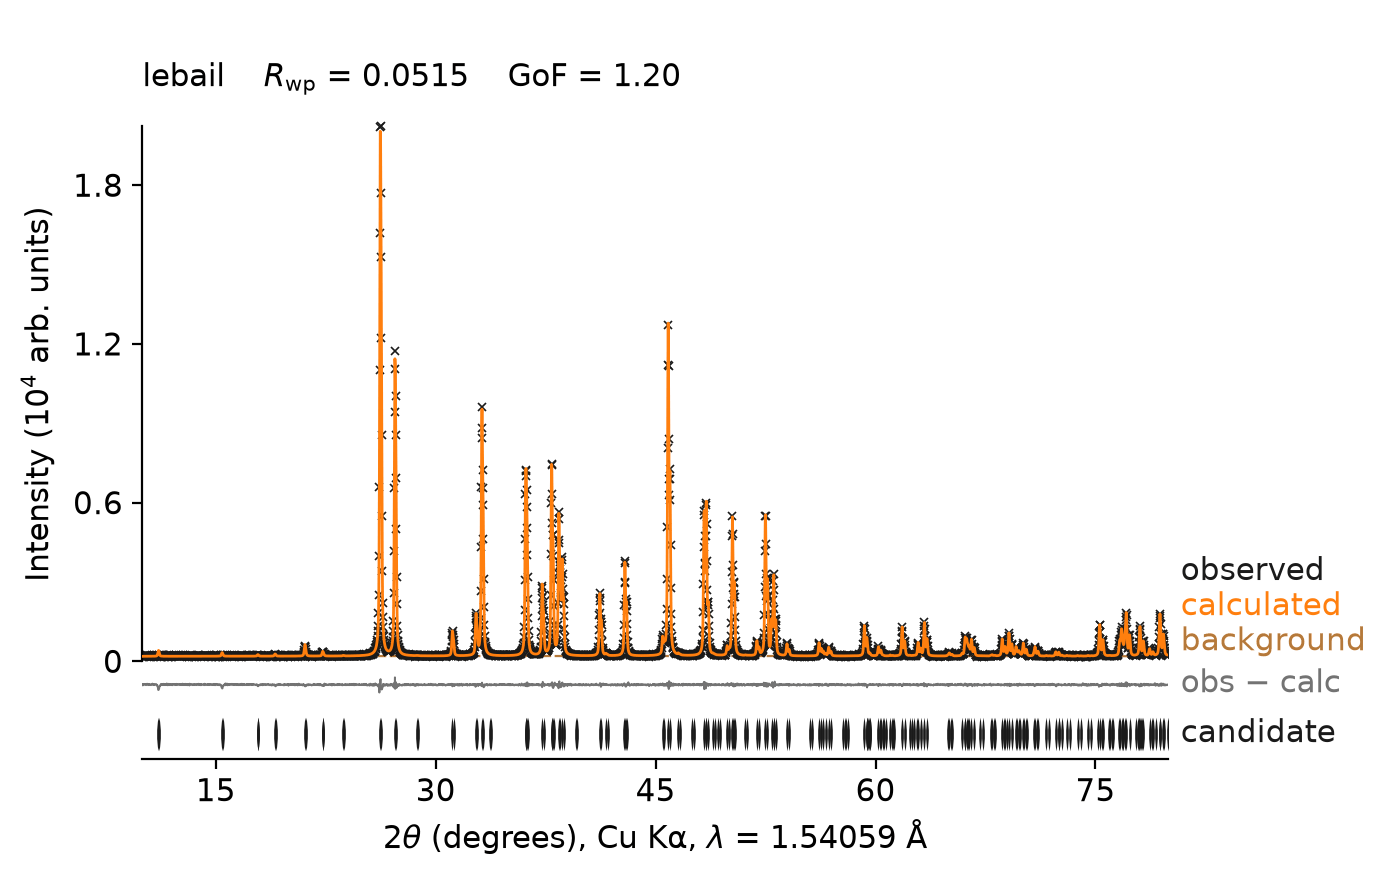

In [10]:
best.plot()

The fit puts a reflection under every peak and leaves only small residuals, so the lattice is right.

Some ticks stand over no peak, such as those near 11° and 15.5°.
They are reflections `P m m m` allows and aragonite's glide planes remove.

What this does not settle is the space group.
That is a question about [which reflections are absent](https://rietx.org/docs/stable/reference/indexing-evidence.html#the-extinction-symbol), and it comes after the cell is refined.